# How good are LLMs at 20 Questions? Evaluation of the final runs

This notebook evaluates the **final v2 runs** (3,000 games, completed 2026-11-26) against the
research questions and evaluation plan in `project_proposal.md`:

| Research question | Evidence used here |
|---|---|
| **RQ1** Guesser, answerer, and pairing effects; does a model play better against itself? | E1 round robin (16 directed pairings × 40 shared targets); E2 predictable-minds (16 pairings on model-picked secrets) |
| **RQ2** Are "random" secret picks random? Is the bias exploitable? | E2 picks (100 per model) vs a uniform sampler; E2 scouting (matched games with/without the opponent's top-5 report) |
| **RQ3** How much information does each question gain vs the ideal 1 bit? | E5 exact-information pilot; E6 reasoning budgets; E1 behavioral proxies |
| **RQ4** How often are answers wrong, and how costly is a wrong answer? | Category-keyed answers across E1–E4; E3 liar and E4 noisy-oracle games vs theoretical references |

All numbers are computed by `src/analysis/evaluation.py` (tested in `tests/test_evaluation.py`),
which reuses the experiment runners' own summary code where it exists. Uncertainty follows the
proposal: **target-clustered or paired bootstrap 95% intervals**, **paired sign-flip permutation
tests**, and **Holm correction** within each family of comparisons. Use the kernel
**llmat20qs analysis**.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "analysis").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.analysis import evaluation as ev

pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_colwidth", 80)
MODELS, LABELS = ev.MODELS, {**ev.LABELS, "gemma3-12b-it": "Gemma 3 12B",
                             "mistral-nemo-12b": "Mistral Nemo 12B", "granite-3.3-8b": "Granite 3.3 8B"}

# Chart style: validated reference palette in fixed model (registry) order; recessive axes.
COLORS = dict(zip(MODELS, ["#257de0", "#f47230", "#00b894", "#f2a600"]))
INK, INK2, GRID = "#191919", "#666666", "#e7e7e7"
BLUES = ["#eaf2fc", "#c3dbf7", "#8dbbf0", "#4f97e6", "#257de0", "#1a5aa6", "#123e73"]
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

PCT = plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0)

def pct(x):
    return f"{x:.0%}"

def label_models(frame, axis=0):
    return frame.rename(LABELS, axis=axis)

def interval_dots(ax, values, lows, highs, labels, colors, xlabel):
    y = np.arange(len(values))
    for yi, v, lo, hi, c in zip(y, values, lows, highs, colors):
        ax.plot([lo, hi], [yi, yi], color=c, linewidth=2, solid_capstyle="round")
        ax.scatter([v], [yi], s=60, color=c, edgecolor="white", linewidth=2, zorder=3)
    ax.set_yticks(y, labels)
    if not ax.yaxis_inverted():  # shared axes would otherwise flip back
        ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)

## 0. Data validity

Every game file must have the expected number of unique records, no mock records, and the
corrected protocol: `guess_rule = listed-candidate-guess-spends-turn-v2` for E1–E4 (a wrong
listed guess spends a turn) and the current-state-only dialogue for E5/E6. The invalid v1
runs (free wrong guesses) are evaluated separately in `v1_salvage_evaluation.ipynb` and are
**not** used here.

In [2]:
inventory = ev.inventory()
assert (inventory["records"] == inventory["expected"]).all()
assert (inventory["unique_ids"] == inventory["records"]).all()
assert (inventory["mock_records"] == 0).all()
inventory

,dataset,file,records,expected,unique_ids,protocol,mock_records
0,e1_cross,e1-cross-play-r1.jsonl,480,480,480,listed-candidate-guess-spends-turn-v2,0
1,e1_self,e1-self-play-r1.jsonl,160,160,160,listed-candidate-guess-spends-turn-v2,0
2,e2_picks,e2-predictable-picks-s519.jsonl,400,400,400,-,0
3,e2_predictable,e2-predictable-games-s519.jsonl,640,640,640,listed-candidate-guess-spends-turn-v2,0
4,e2_scouting,e2-scouting-s519.jsonl,640,640,640,listed-candidate-guess-spends-turn-v2,0
5,e3,e3-liar-s519.jsonl,500,500,500,listed-candidate-guess-spends-turn-v2,0
6,e4,e4-noisy-s519.jsonl,300,300,300,listed-candidate-guess-spends-turn-v2,0
7,e5,e5-exact-information-s519.jsonl,160,160,160,listed-candidate-guess-spends-turn-v2,0
8,e6,e6-reasoning-budget-s519.jsonl,120,120,120,listed-candidate-guess-spends-turn-v2,0


The E5/E6 rows show the guess rule because their run config carries it too; their dialogue
version (`current-state-only-v2`) is checked by the runner on resume. Total: **3,000 games**
plus 400 target picks.

## 1. RQ1 — Guesser, answerer, and pairing (E1)

E1 plays all 16 directed pairings of the four models (including 4 self-play pairings) on the
same 40 targets (10 per category, 5 common + 5 rare). The guesser sees the 40-candidate list, so
an ideal binary search needs log₂ 40 ≈ 5.3 questions.

### 1.1 Win-rate matrix

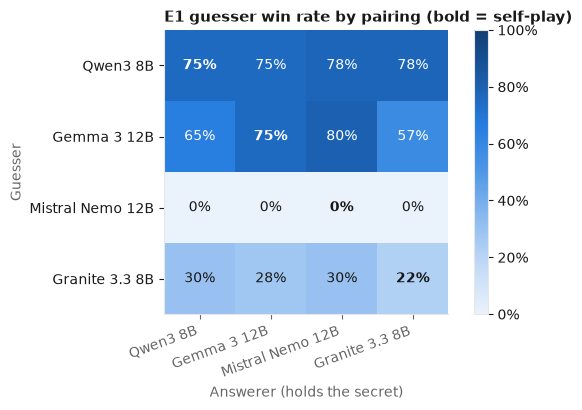

,guesser,answerer,self_play,games,win_rate,ci_low,ci_high,mean_turns,invalid_moves_per_game,invalid_answers_per_game
0,Qwen3 8B,Qwen3 8B,True,40,0.750,0.625,0.875,13.425,0.000,0.000
1,Gemma 3 12B,Qwen3 8B,False,40,0.650,0.500,0.800,15.900,0.000,0.000
2,Mistral Nemo 12B,Qwen3 8B,False,40,0.000,0.000,0.000,20.000,0.000,0.000
3,Granite 3.3 8B,Qwen3 8B,False,40,0.300,0.175,0.450,16.700,1.750,0.000
4,Qwen3 8B,Gemma 3 12B,False,40,0.750,0.625,0.875,12.425,0.225,0.000
5,Gemma 3 12B,Gemma 3 12B,True,40,0.750,0.600,0.875,15.625,0.000,0.000
6,Mistral Nemo 12B,Gemma 3 12B,False,40,0.000,0.000,0.000,20.000,0.000,0.000
7,Granite 3.3 8B,Gemma 3 12B,False,40,0.275,0.150,0.425,17.400,0.750,0.000
8,Qwen3 8B,Mistral Nemo 12B,False,40,0.775,0.650,0.900,12.850,0.400,0.000
9,Gemma 3 12B,Mistral Nemo 12B,False,40,0.800,0.675,0.925,14.925,0.000,0.000


In [3]:
e1_summary = ev.e1_summary()
matrix = ev.e1_win_matrix(e1_summary)
fig, ax = plt.subplots(figsize=(6.2, 4.2))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blues", BLUES)
image = ax.imshow(matrix.to_numpy(), cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(4), [LABELS[m] for m in MODELS], rotation=20, ha="right")
ax.set_yticks(range(4), [LABELS[m] for m in MODELS])
ax.set_xlabel("Answerer (holds the secret)")
ax.set_ylabel("Guesser")
ax.grid(False)
for i in range(4):
    for j in range(4):
        value = matrix.iloc[i, j]
        ax.text(j, i, pct(value), ha="center", va="center", fontsize=10,
                color="white" if value > 0.55 else INK,
                fontweight="bold" if i == j else "normal")
ax.set_title("E1 guesser win rate by pairing (bold = self-play)")
fig.colorbar(image, ax=ax, fraction=0.04, format=PCT)
plt.tight_layout(); plt.show()

pairings = ev.e1_pairings(e1_summary)
pairings.assign(guesser=pairings.guesser.map(LABELS), answerer=pairings.answerer.map(LABELS))

Rows differ far more than columns: **who guesses matters; who answers barely does.**

### 1.2 Role effects with target-clustered intervals and paired tests

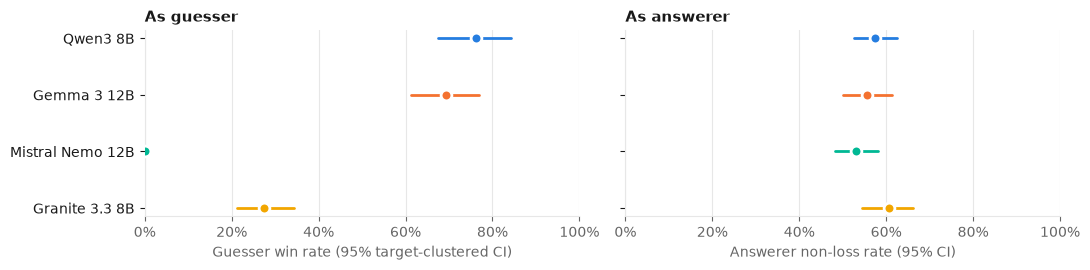

**Guesser comparisons** (paired by target, sign-flip test, Holm-adjusted):

,model_a,model_b,difference_a_minus_b,ci_low,ci_high,p_value,holm_p
0,Qwen3 8B,Gemma 3 12B,0.069,-0.050,0.181,0.293,0.293
1,Qwen3 8B,Mistral Nemo 12B,0.762,0.675,0.850,0.000,0.001
2,Qwen3 8B,Granite 3.3 8B,0.487,0.350,0.606,0.000,0.001
3,Gemma 3 12B,Mistral Nemo 12B,0.694,0.619,0.762,0.000,0.001
4,Gemma 3 12B,Granite 3.3 8B,0.419,0.300,0.531,0.000,0.001
5,Mistral Nemo 12B,Granite 3.3 8B,-0.275,-0.344,-0.212,0.000,0.001


**Answerer comparisons** (answerer 'wins' when the guesser fails):

,model_a,model_b,difference_a_minus_b,ci_low,ci_high,p_value,holm_p
0,Qwen3 8B,Gemma 3 12B,0.019,-0.050,0.087,0.719,1.000
1,Qwen3 8B,Mistral Nemo 12B,0.044,-0.031,0.119,0.358,1.000
2,Qwen3 8B,Granite 3.3 8B,-0.031,-0.113,0.050,0.553,1.000
3,Gemma 3 12B,Mistral Nemo 12B,0.025,-0.050,0.100,0.642,1.000
4,Gemma 3 12B,Granite 3.3 8B,-0.050,-0.131,0.031,0.321,1.000
5,Mistral Nemo 12B,Granite 3.3 8B,-0.075,-0.150,0.006,0.096,0.574


In [4]:
roles = ev.e1_roles(e1_summary)
fig, axes = plt.subplots(1, 2, figsize=(11, 2.8), sharey=True)
interval_dots(axes[0], roles.guesser_win_rate, [c[0] for c in roles.guesser_ci],
              [c[1] for c in roles.guesser_ci], [LABELS[m] for m in roles.index],
              [COLORS[m] for m in roles.index], "Guesser win rate (95% target-clustered CI)")
interval_dots(axes[1], roles.answerer_nonloss_rate, [c[0] for c in roles.answerer_ci],
              [c[1] for c in roles.answerer_ci], [LABELS[m] for m in roles.index],
              [COLORS[m] for m in roles.index], "Answerer non-loss rate (95% CI)")
for ax in axes:
    ax.xaxis.set_major_formatter(PCT); ax.set_xlim(0, 1)
axes[0].set_title("As guesser"); axes[1].set_title("As answerer")
plt.tight_layout(); plt.show()
display(Markdown("**Guesser comparisons** (paired by target, sign-flip test, Holm-adjusted):"))
display(ev.e1_role_comparisons(e1_summary, "guesser").replace(LABELS))
display(Markdown("**Answerer comparisons** (answerer 'wins' when the guesser fails):"))
display(ev.e1_role_comparisons(e1_summary, "answerer").replace(LABELS))

* **Guesser ranking:** Qwen3 ≈ Gemma 3 ≫ Granite ≫ Mistral. Qwen3 vs Gemma is not
  significant; every other guesser difference survives Holm correction.
* **Answerers are indistinguishable** on outcome: no answerer comparison is significant.
* **Mistral never wins as guesser (0/160)** because it never guesses (see 1.5), not because
  it is misled.

### 1.3 Does a model play better against itself?

Two complementary analyses:

1. **Matched comparison:** for each guesser, self-play win minus the mean of its three
   cross-play wins on the *same target*. This mixes the self effect with the answerer's skill.
2. **Additive model:** a linear probability model of a win with guesser, answerer,
   same-model, category and rarity terms, with standard errors clustered by target. The
   *same model* coefficient is the self-play effect **beyond** the guesser and answerer main
   effects (the "combination" term of RQ1). A linear model is used because Mistral's 0% win
   rate causes perfect separation in a logistic model.

,guesser,self_play_win_rate,n_pairs,mean_difference,ci_low,ci_high,p_value,holm_p
0,Qwen3 8B,0.750,40,-0.017,-0.150,0.125,0.909,1.000
1,Gemma 3 12B,0.750,40,0.075,-0.067,0.208,0.360,1.000
2,Mistral Nemo 12B,0.000,40,0.000,0.000,0.000,1.000,1.000
3,Granite 3.3 8B,0.225,40,-0.067,-0.217,0.092,0.468,1.000


,estimate,se,ci_low,ci_high,p_value
intercept,0.771,0.053,0.668,0.874,0.000
guesser: gemma3-12b-it,-0.069,0.059,-0.185,0.047,0.246
guesser: mistral-nemo-12b,-0.762,0.046,-0.853,-0.672,0.000
guesser: granite-3.3-8b,-0.487,0.069,-0.622,-0.353,0.000
answerer: gemma3-12b-it,0.019,0.035,-0.051,0.088,0.597
answerer: mistral-nemo-12b,0.044,0.041,-0.037,0.125,0.289
answerer: granite-3.3-8b,-0.031,0.043,-0.115,0.052,0.462
same model (self-play),-0.002,0.030,-0.061,0.057,0.945
category: animal,-0.037,0.038,-0.112,0.037,0.327
category: place,-0.050,0.034,-0.117,0.017,0.142


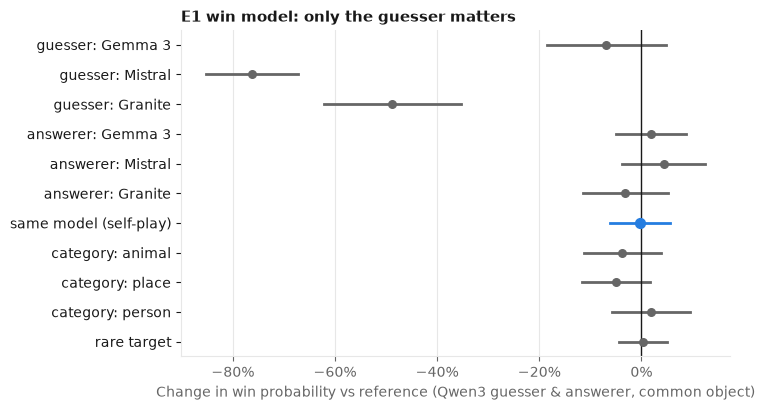

In [5]:
self_play = ev.e1_self_play_matched()
display(self_play.assign(guesser=self_play.guesser.map(LABELS)))

regression = ev.e1_regression()
display(regression)
terms = regression.drop(index="intercept")
fig, ax = plt.subplots(figsize=(7.5, 4.2))
y = np.arange(len(terms))
highlight = terms.index == "same model (self-play)"
for yi, (name, row), hi in zip(y, terms.iterrows(), highlight):
    color = "#257de0" if hi else INK2
    ax.plot([row.ci_low, row.ci_high], [yi, yi], color=color, linewidth=2)
    ax.scatter([row.estimate], [yi], s=50 if hi else 30, color=color, zorder=3)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(y, [t.replace("qwen3-8b", "Qwen3").replace("gemma3-12b-it", "Gemma 3")
                  .replace("mistral-nemo-12b", "Mistral").replace("granite-3.3-8b", "Granite")
                  for t in terms.index])
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(PCT)
ax.set_xlabel("Change in win probability vs reference (Qwen3 guesser & answerer, common object)")
ax.set_title("E1 win model: only the guesser matters")
plt.tight_layout(); plt.show()

**No self-play advantage.** The same-model coefficient is ≈ 0 percentage points with a
95% CI of roughly ±6 pp, and no guesser's matched self-vs-cross difference is significant. Once
the guesser is known, neither the answerer's identity, the target category nor rarity
measurably changes the win rate.

### 1.4 When are games won? (survival view)

Games end at a correct guess or at the 20-turn cap, so the cumulative share won by turn *t*
is the complement of a Kaplan–Meier survival curve with censoring only at turn 20.

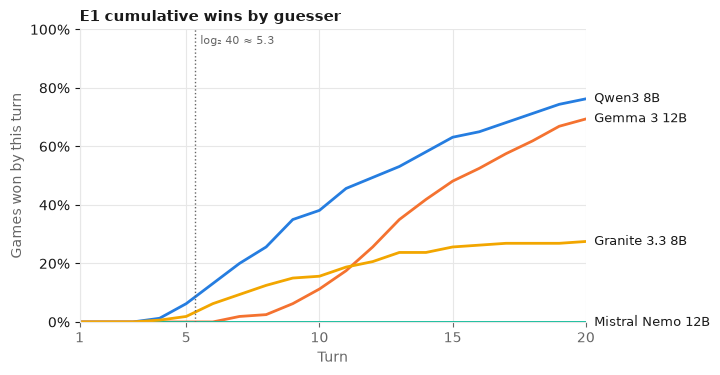

**Win rate by target category and rarity** (guesser rows):

,animal,object,person,place,common,rare
Qwen3 8B,0.600,0.850,0.950,0.650,0.738,0.787
Gemma 3 12B,0.625,0.725,0.725,0.700,0.700,0.688
Mistral Nemo 12B,0.000,0.000,0.000,0.000,0.000,0.000
Granite 3.3 8B,0.425,0.225,0.200,0.250,0.287,0.263


In [6]:
curves = ev.cumulative_wins(ev.e1_records())
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for model in MODELS:
    ax.plot(curves.index, curves[model], color=COLORS[model], linewidth=2)
    ax.annotate(LABELS[model], (20, curves[model].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK)
ax.axvline(np.log2(40), color=INK2, linestyle=":", linewidth=1)
ax.annotate("log₂ 40 ≈ 5.3", (np.log2(40), 0.95), xytext=(4, 0), textcoords="offset points",
            fontsize=8, color=INK2)
ax.set_xlim(1, 20); ax.set_ylim(0, 1); ax.set_xticks([1, 5, 10, 15, 20])
ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Turn"); ax.set_ylabel("Games won by this turn")
ax.set_title("E1 cumulative wins by guesser")
plt.subplots_adjust(right=0.8); plt.show()

display(Markdown("**Win rate by target category and rarity** (guesser rows):"))
display(label_models(ev.win_by_stratum(ev.e1_records(), "category")
                     .join(ev.win_by_stratum(ev.e1_records(), "frequency"))))

### 1.5 Guesser behavior

* *Guess precision* is correct guesses / all guesses.
* *Repeated question rate* counts questions asked verbatim earlier in the same game.
* *Determined category questions* are category questions ("Is it an animal/person/place/
  object?") whose answer already followed from earlier category answers. These waste the turn
  (0 bits), a proxy for the proposal's "questions asked after the answer was already
  determined".

In [7]:
behavior = ev.guesser_behavior(ev.e1_records())
label_models(behavior)

,games,invalid_moves_per_game,guesses_per_game,guess_precision,games_without_guess,median_first_guess_turn,repeated_question_rate,category_question_share,determined_category_question_rate
guesser,,,,,,,,,
Qwen3 8B,160,0.156,2.712,0.281,0.013,7.000,0.004,0.218,0.137
Gemma 3 12B,160,0.000,0.881,0.787,0.156,14.000,0.002,0.131,0.087
Mistral Nemo 12B,160,0.000,0.000,NaN,1.000,NaN,0.359,0.296,0.688
Granite 3.3 8B,160,1.444,1.925,0.143,0.375,8.000,0.018,0.028,0.000


* **Qwen3 guesses early and often** (median first guess at turn 7, about 2.7 guesses per
  game, 28% precision). Under the corrected rule each wrong guess costs a turn, and it still
  wins the most.
* **Gemma 3 is conservative:** it guesses late (median turn 14) but is right 79% of the time.
  It makes no guess at all in 16% of games.
* **Mistral never guesses.** It also repeats 36% of its questions and asks already-determined
  category questions 69% of the time: its search loops rather than narrowing.
* **Granite** has the most malformed moves (1.4 per game) and low guess precision.

### 1.6 Do the E1 results generalize? E2 predictable-minds pairings

E2 replays the round robin on **model-picked secrets** with the **full 128-candidate list**
(ideal ≈ 7 questions). The same answerer picks are played by every guesser, so guessers are
compared on matched secrets.

In [8]:
display(Markdown("**E2 predictable-minds win rate** (guesser rows × answerer columns):"))
display(label_models(label_models(ev.e2_predictable_matrix()), axis=1))
display(ev.e2_predictable_guesser_comparisons().replace(LABELS))
display(Markdown("**Guesser behavior across the 128-candidate experiments:**"))
display(pd.concat({name: ev.guesser_behavior(list(ev.load(name)))[
    ["guesses_per_game", "games_without_guess", "guess_precision", "repeated_question_rate"]]
    for name in ("e2_predictable", "e2_scouting", "e3", "e4")}).rename(LABELS, level=1))

**E2 predictable-minds win rate** (guesser rows × answerer columns):

,Qwen3 8B,Gemma 3 12B,Mistral Nemo 12B,Granite 3.3 8B
Qwen3 8B,0.425,0.325,0.375,0.400
Gemma 3 12B,0.000,0.000,0.000,0.000
Mistral Nemo 12B,0.000,0.000,0.050,0.000
Granite 3.3 8B,0.175,0.025,0.175,0.075


,model_a,model_b,n_pairs,mean_difference,ci_low,ci_high,p_value,holm_p
0,Qwen3 8B,Gemma 3 12B,160,0.381,0.306,0.456,0.000,0.001
1,Qwen3 8B,Mistral Nemo 12B,160,0.369,0.294,0.450,0.000,0.001
2,Qwen3 8B,Granite 3.3 8B,160,0.269,0.188,0.350,0.000,0.001
3,Gemma 3 12B,Mistral Nemo 12B,160,-0.013,-0.031,0.000,0.505,0.505
4,Gemma 3 12B,Granite 3.3 8B,160,-0.113,-0.163,-0.062,0.000,0.001
5,Mistral Nemo 12B,Granite 3.3 8B,160,-0.100,-0.156,-0.050,0.000,0.001


**Guesser behavior across the 128-candidate experiments:**

guesses_per_game  games_without_guess  \
               guesser                                                   
e2_predictable Qwen3 8B                     4.094                0.025   
               Gemma 3 12B                  0.000                1.000   
               Mistral Nemo 12B             0.113                0.900   
               Granite 3.3 8B               1.481                0.588   
e2_scouting    Qwen3 8B                     4.044                0.006   
               Gemma 3 12B                  0.000                1.000   
               Mistral Nemo 12B             0.281                0.725   
               Granite 3.3 8B               1.962                0.481   
e3             Qwen3 8B                     4.190                0.008   
               Gemma 3 12B                  0.000                1.000   
               Mistral Nemo 12B             0.129                0.871   
               Granite 3.3 8B               1.435                0.548   
e4             Qwen3 8B                     4.573                0.000   
               Gemma 3 12B                  0.000                1.000   
               Mistral Nemo 12B             0.133                0.867   
               Granite 3.3 8B               1.507                0.507   

                                 guess_precision  repeated_question_rate  
               guesser                                                    
e2_predictable Qwen3 8B                    0.093                   0.000  
               Gemma 3 12B                   NaN                   0.012  
               Mistral Nemo 12B            0.111                   0.618  
               Granite 3.3 8B              0.076                   0.028  
e2_scouting    Qwen3 8B                    0.156                   0.001  
               Gemma 3 12B                   NaN                   0.008  
               Mistral Nemo 12B            0.289                   0.588  
               Granite 3.3 8B              0.076                   0.014  
e3             Qwen3 8B                    0.072                   0.001  
               Gemma 3 12B                   NaN                   0.010  
               Mistral Nemo 12B            0.000                   0.673  
               Granite 3.3 8B              0.051                   0.012  
e4             Qwen3 8B                    0.058                   0.004  
               Gemma 3 12B                   NaN                   0.016  
               Mistral Nemo 12B            0.000                   0.650  
               Granite 3.3 8B              0.000                   0.048

With 128 candidates **Qwen3 is the only competent guesser** (38% vs ≤13% for every other
model; all comparisons with Qwen3 significant after Holm).

* **Gemma 3 drops from 69% in E1 to 0%** because in all 521 of its E2–E4 games it never makes a
  single guess, even after narrowing to the answer. For example, it confirmed "Is it the
  tallest land animal?" on turn 10, then asked 10 more questions about the giraffe.
* The ranking therefore depends on the guess decision, not only on question quality.
* **Caveat:** E1 and E2–E4 differ in both the list length (40 vs 128) and the prompt wording, so
  this design cannot say which of the two causes Gemma's guess aversion.

## 2. RQ2 — How random are "random" secrets? (E2 picks)

Each model picked 100 secrets from the fixed 128-concept pool, 25 per category, and was asked
to choose at random. The reference is a **truly uniform sampler** with the same
25-per-category constraint.

* **Entropy:** both the plug-in estimate and the Miller–Madow bias-corrected estimate.
* **Uniformity test:** a χ² statistic within categories, with a Monte Carlo p-value from
  10,000 uniform draws.
* **Exploitable gap:** log₂ 128 − H estimates how many questions per game an opponent who
  knew the pick distribution could save (proposal, *Randomness*).

,picks,distinct,entropy_bits,entropy_mm_bits,gap_log2N_minus_H,chi_square,chi_square_mc_p,rare_share,rare_ci,top_picks
model,,,,,,,,,,
Qwen3 8B,100,8,2.452,2.503,4.497,2562.400,0.000,0.790,"(0.7002, 0.858343)","sextant (25), pangolin (25), salar-de-uyuni (21), leonardo-da-vinci (19), ma..."
Gemma 3 12B,100,8,2.505,2.555,4.445,2524.000,0.000,0.930,"(0.862505, 0.965681)","sextant (25), svalbard (25), zheng-he (25), wombat (10), giraffe (7)"
Mistral Nemo 12B,100,19,3.469,3.599,3.401,1569.120,0.000,0.120,"(0.069994, 0.198121)","spoon (22), albert-einstein (22), paris (12), dog (10), timbuktu (4)"
Granite 3.3 8B,100,15,3.338,3.438,3.562,1535.840,0.000,0.410,"(0.318673, 0.507986)","ada-lovelace (25), penguin (14), salar-de-uyuni (14), dolphin (8), toothbrus..."


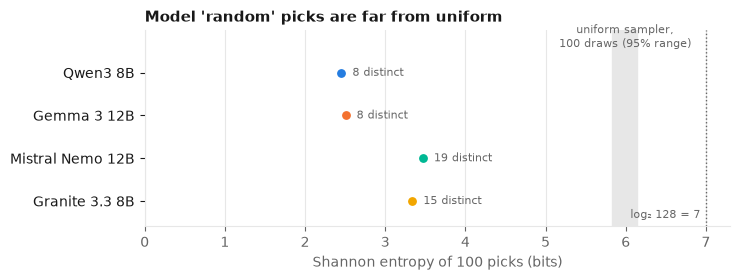

Uniform sampler, 100 draws: mean plug-in entropy 5.99 bits (95% range 5.83-6.14).


In [9]:
picks = ev.pick_uniformity()
uniform_mean, uniform_low, uniform_high = ev.uniform_entropy_reference()
display(label_models(picks))

fig, ax = plt.subplots(figsize=(7.5, 2.9))
ax.axvspan(uniform_low, uniform_high, color=GRID, zorder=0)
ax.annotate("uniform sampler,\n100 draws (95% range)", (uniform_mean, -0.6), ha="center",
            fontsize=8, color=INK2)
ax.axvline(7, color=INK2, linestyle=":", linewidth=1)
ax.annotate("log₂ 128 = 7", (7, 3.4), xytext=(-4, 0), textcoords="offset points", ha="right",
            fontsize=8, color=INK2)
for y, model in enumerate(MODELS):
    ax.scatter(picks.loc[model, "entropy_bits"], y, s=70, color=COLORS[model],
               edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(f"{picks.loc[model, 'distinct']} distinct", (picks.loc[model, "entropy_bits"], y),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=8, color=INK2)
ax.set_yticks(range(4), [LABELS[m] for m in MODELS]); ax.invert_yaxis()
ax.set_ylim(3.6, -1.0); ax.set_xlim(0, 7.3); ax.grid(axis="y", visible=False)
ax.set_xlabel("Shannon entropy of 100 picks (bits)")
ax.set_title("Model 'random' picks are far from uniform")
plt.tight_layout(); plt.show()
print(f"Uniform sampler, 100 draws: mean plug-in entropy {uniform_mean:.2f} bits "
      f"(95% range {uniform_low:.2f}-{uniform_high:.2f}).")

**Models are not random.** Every model's entropy is far below the uniform sampler's
range (χ² Monte Carlo p < 0.0001 for all four).

* **Qwen3 and Gemma 3** use only 8 distinct secrets out of 128. Each picks the same concept in
  all 25 draws for some categories (for example "sextant" for objects).
* **Mistral and Granite** spread somewhat wider (15–19 distinct) but still concentrate on
  favorites.
* **Rarity bias differs by model:** Qwen3 and Gemma 3 favor the "rare" stratum (79% and 93%
  against 50% for uniform), while Mistral favors common concepts (12% rare).
* **Exploitable gap:** about 3.4–4.5 bits per game. In principle an informed opponent could
  save that many questions.

### 2.1 Does the bias actually help an opponent? (E2 scouting)

In self-play, each guesser played 80 matched secrets **with and without** a report of the
answerer's top-5 favorite picks. Same secret, same answerer, only the report differs.

,pairs,win_rate_no_report,win_rate_report,win_diff,win_ci,win_p,turns_saved,turns_saved_ci,turns_p,secret_in_report_share,win_holm_p,turns_holm_p
model,,,,,,,,,,,,
Qwen3 8B,80,0.463,0.800,0.338,"(0.2, 0.475)",0.000,5.700,"(3.8375, 7.587813)",0.000,0.925,0.000,0.000
Gemma 3 12B,80,0.000,0.000,0.000,"(0.0, 0.0)",1.000,-0.000,"(-0.0, -0.0)",1.000,0.912,1.000,1.000
Mistral Nemo 12B,80,0.062,0.100,0.037,"(-0.0375, 0.1125)",0.503,0.562,"(-0.5375, 1.712812)",0.377,0.700,1.000,0.755
Granite 3.3 8B,80,0.087,0.212,0.125,"(0.025, 0.2375)",0.038,1.712,"(0.537188, 2.95)",0.005,0.662,0.115,0.016


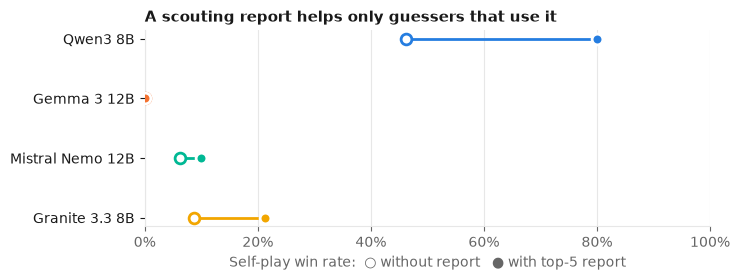

In [10]:
scouting = ev.scouting_effect()
display(label_models(scouting))
fig, ax = plt.subplots(figsize=(7.5, 2.9))
for y, model in enumerate(MODELS):
    a, b = scouting.loc[model, ["win_rate_no_report", "win_rate_report"]]
    ax.plot([a, b], [y, y], color=COLORS[model], linewidth=2)
    ax.scatter([a], [y], s=60, color="white", edgecolor=COLORS[model], linewidth=2, zorder=3)
    ax.scatter([b], [y], s=60, color=COLORS[model], edgecolor="white", linewidth=2, zorder=3)
ax.set_yticks(range(4), [LABELS[m] for m in MODELS]); ax.invert_yaxis()
ax.grid(axis="y", visible=False); ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PCT)
ax.set_xlabel("Self-play win rate:  ○ without report   ● with top-5 report")
ax.set_title("A scouting report helps only guessers that use it")
plt.tight_layout(); plt.show()

The secret was in the report in 66–93% of games, so the report was highly informative.

* **Qwen3 exploits it:** win rate 46% → 80% (+34 pp, Holm p < 0.001), saving 5.7 turns per
  game. That is in line with, even slightly above, the 4.5-bit entropy gap for Qwen3's pick
  distribution.
* **Granite gains modestly:** +12.5 pp wins and 1.7 turns saved; only the turns gain survives
  Holm correction.
* **Gemma 3 and Mistral gain nothing,** because they still almost never guess. Predictability
  is only a vulnerability against an opponent willing to act on it.

## 3. RQ3 — How informative are the questions? (E5, E6)

E1's free-form questions have no answer key, so their information gain cannot be measured
exactly. E5 makes it measurable:

* Each model plays the 40 E1 targets against a **deterministic oracle** and chooses each
  question from a fixed bank of 54 binary predicates with exact labels.
* For every question asked, we know the expected information gain H(p) given the remaining
  candidates, and the **best available** question's gain. Their ratio is the *optimality
  ratio*.
* **Baselines:** a greedy max-information player and a random-question player.
* The ideal is ⌈log₂ 40⌉ = 6 questions.
* When one candidate remains the controller guesses automatically (`forced_guess`), so turns
  measure search efficiency.
* The menu only offers questions that split the remaining set, so 0-bit questions cannot occur.

model,Qwen3 8B,Gemma 3 12B,Mistral Nemo 12B,Granite 3.3 8B
games,40.000,40.000,40.000,40.000
win_rate,1.000,1.000,0.575,0.350
mean_turns,7.975,7.325,14.300,17.475
questions_per_game,6.950,6.325,5.950,2.625
bits_per_question,0.789,0.844,0.585,0.820
best_available_bits,0.900,0.886,0.951,0.912
optimality_ratio,0.886,0.957,0.622,0.907
below_half_best_rate,0.036,0.000,0.387,0.010
invalid_action_rate,0.003,0.000,0.479,0.701
voluntary_guesses_per_game,0.000,0.000,1.225,2.375


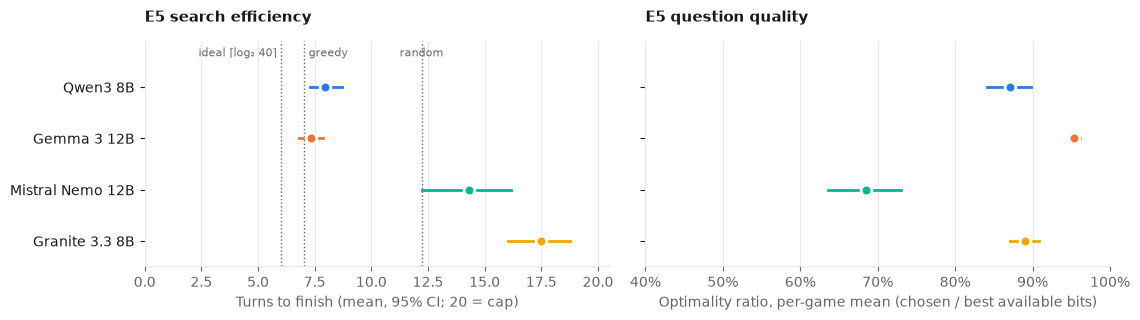

**Models vs baselines** (model turns − baseline turns, paired by target):

,model,baseline,n_pairs,mean_difference,ci_low,ci_high,p_value
0,Qwen3 8B,greedy,40,0.925,-0.051,1.900,0.092
1,Qwen3 8B,random,40,-4.600,-6.376,-2.849,0.000
2,Gemma 3 12B,greedy,40,0.275,-0.400,0.950,0.484
3,Gemma 3 12B,random,40,-4.000,-5.876,-2.200,0.001
4,Mistral Nemo 12B,greedy,40,7.250,5.324,9.100,0.000
5,Mistral Nemo 12B,random,40,1.975,-0.651,4.601,0.139
6,Granite 3.3 8B,greedy,40,10.425,8.925,11.725,0.000
7,Granite 3.3 8B,random,40,4.825,2.825,6.900,0.000


**Pairwise model comparisons** (paired by target, Holm within metric):

,model_a,model_b,metric,n_pairs,mean_difference,ci_low,ci_high,p_value,holm_p
0,Qwen3 8B,Gemma 3 12B,turns,40,0.650,-0.225,1.575,0.179,0.179
1,Qwen3 8B,Mistral Nemo 12B,turns,40,-6.325,-8.250,-4.374,0.000,0.001
2,Qwen3 8B,Granite 3.3 8B,turns,40,-9.500,-11.125,-7.775,0.000,0.001
3,Gemma 3 12B,Mistral Nemo 12B,turns,40,-6.975,-9.000,-5.050,0.000,0.001
4,Gemma 3 12B,Granite 3.3 8B,turns,40,-10.150,-11.451,-8.750,0.000,0.001
5,Mistral Nemo 12B,Granite 3.3 8B,turns,40,-3.175,-5.575,-0.774,0.013,0.025
0,Qwen3 8B,Gemma 3 12B,optimality,40,-0.084,-0.115,-0.056,0.000,0.001
1,Qwen3 8B,Mistral Nemo 12B,optimality,40,0.186,0.140,0.230,0.000,0.001
2,Qwen3 8B,Granite 3.3 8B,optimality,38,-0.015,-0.046,0.016,0.377,0.377
3,Gemma 3 12B,Mistral Nemo 12B,optimality,40,0.270,0.223,0.316,0.000,0.001


In [11]:
quality = ev.e5_question_quality()
display(label_models(quality).T)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.3), sharey=True)
games = ev.e5_game_metrics()
for y, model in enumerate(MODELS):
    subset = games[games.model == model]
    low, high = ev.bootstrap_ci(subset.turns, ev.SEED + y)
    axes[0].plot([low, high], [y, y], color=COLORS[model], linewidth=2)
    axes[0].scatter(subset.turns.mean(), y, s=60, color=COLORS[model], edgecolor="white",
                    linewidth=2, zorder=3)
    low, high = ev.bootstrap_ci(subset.optimality.dropna(), ev.SEED + 10 + y)
    axes[1].plot([low, high], [y, y], color=COLORS[model], linewidth=2)
    axes[1].scatter(subset.optimality.mean(), y, s=60, color=COLORS[model], edgecolor="white",
                    linewidth=2, zorder=3)
for value, name, ha, dx in ((quality.greedy_turns.iloc[0], "greedy", "left", 3),
                           (quality.random_turns.mean(), "random", "center", 0),
                           (6, "ideal ⌈log₂ 40⌉", "right", -3)):
    axes[0].axvline(value, color=INK2, linestyle=":", linewidth=1)
    axes[0].annotate(name, (value, -0.55), xytext=(dx, 0), textcoords="offset points",
                     fontsize=8, color=INK2, ha=ha, va="bottom")
axes[0].set_xlabel("Turns to finish (mean, 95% CI; 20 = cap)"); axes[0].set_xlim(0, 20.5)
axes[1].set_xlabel("Optimality ratio, per-game mean (chosen / best available bits)"); axes[1].set_xlim(0.4, 1)
axes[1].xaxis.set_major_formatter(PCT)
axes[0].set_yticks(range(4), [LABELS[m] for m in MODELS]); axes[0].set_ylim(3.5, -0.9)
for ax in axes: ax.grid(axis="y", visible=False)
axes[0].set_title("E5 search efficiency", pad=14); axes[1].set_title("E5 question quality", pad=14)
plt.tight_layout(); plt.show()

display(Markdown("**Models vs baselines** (model turns − baseline turns, paired by target):"))
display(ev.e5_vs_greedy().replace(LABELS))
display(Markdown("**Pairwise model comparisons** (paired by target, Holm within metric):"))
display(pd.concat([ev.e5_model_comparisons("turns"),
                   ev.e5_model_comparisons("optimality")]).replace(LABELS))

* **Gemma 3 and Qwen3 ask near-optimal questions.** Their optimality ratios are 96% and
  89% of asked questions (the chart averages per game first), about 0.79–0.84 bits per question against a ceiling of 1. They solve every target in
  7.3–8.0 turns, statistically indistinguishable from the greedy information-maximizer (7.1).
  Both are about 4 turns better than random questioning.
* **Granite chooses good questions (91%) but is the slowest player.** Its 70% invalid-action
  rate means most of its turns are wasted on malformed moves, so it averages 17.5 turns and
  wins only 35%.
* **Mistral chooses poor questions** (62% optimality, significantly below every other model).
  It also makes 48% invalid actions, which leaves it no better than random questioning.
* **In the free-form E1 games** (section 1.5), Mistral's 36% repeats and 69% already-determined
  category questions are 0-bit questions. Qwen3 and Gemma repeat under 1%.

### 3.1 E6 — Does more thinking buy more bits?

Qwen3 8B replays E5 with thinking **off**, a **256-token**, and a **1024-token** thinking
budget. Targets, question bank, oracle and per-turn sampling seeds are identical, so every
difference is paired by target. Budgets are enforced by budget forcing: `</think>` is inserted
at the cap and the answer is limited to 32 tokens.

,thinking_off,thinking_256,thinking_1024
games,40.000,40.000,40.000
mean_won,1.000,1.000,1.000
mean_turns,7.925,8.550,8.425
mean_mean_question_information_bits,0.785,0.802,0.752
mean_mean_optimality_ratio,0.870,0.903,0.842
mean_invalid_actions,0.000,0.175,0.025
mean_output_tokens,41.550,2138.425,7542.200
mean_thinking_tokens,0.000,2060.300,7475.875
mean_budget_exhausted_rate,0.000,0.988,0.886
mean_generation_seconds,2.968,107.923,375.917


**Paired differences** (target bootstrap CI, sign-flip p, Holm across all 15 tests):

,comparison,metric,n_pairs,mean_difference,ci_low,ci_high,p_value,holm_p
0,thinking_256 − thinking_off,mean_question_information_bits,40,0.017,-0.011,0.043,0.246,0.741
1,thinking_256 − thinking_off,mean_optimality_ratio,40,0.033,0.007,0.062,0.017,0.173
2,thinking_256 − thinking_off,turns,40,0.625,-0.075,1.300,0.101,0.608
3,thinking_256 − thinking_off,invalid_actions,40,0.175,0.049,0.350,0.063,0.504
4,thinking_256 − thinking_off,generation_seconds,40,104.955,94.905,115.720,0.000,0.001
5,thinking_1024 − thinking_off,mean_question_information_bits,40,-0.033,-0.062,-0.002,0.033,0.301
6,thinking_1024 − thinking_off,mean_optimality_ratio,40,-0.028,-0.061,0.003,0.083,0.580
7,thinking_1024 − thinking_off,turns,40,0.500,-0.125,1.125,0.143,0.714
8,thinking_1024 − thinking_off,invalid_actions,40,0.025,0.000,0.075,1.000,1.000
9,thinking_1024 − thinking_off,generation_seconds,40,372.949,334.534,409.935,0.000,0.001


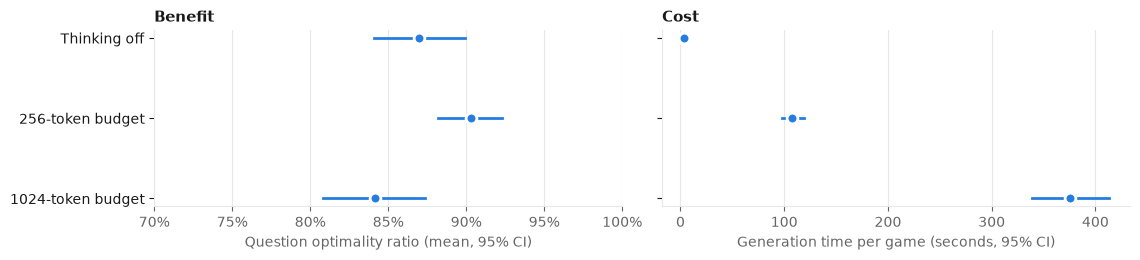

256-token budget vs Thinking off: +0.0079 bits/question per 1k extra tokens
1024-token budget vs Thinking off: -0.0044 bits/question per 1k extra tokens
1024-token budget vs 256-token budget: -0.0093 bits/question per 1k extra tokens


In [12]:
e6_summary = ev.e6_summary()
groups = ev.e6_groups(e6_summary)
display(groups.T)
display(Markdown("**Paired differences** (target bootstrap CI, sign-flip p, Holm across all 15 tests):"))
display(ev.e6_paired_p_values())

order = ["thinking_off", "thinking_256", "thinking_1024"]
names = {"thinking_off": "Thinking off", "thinking_256": "256-token budget",
         "thinking_1024": "1024-token budget"}
metrics = ev.e6_game_metrics()
fig, axes = plt.subplots(1, 2, figsize=(11.5, 2.7), sharey=True)
for y, condition in enumerate(order):
    subset = metrics[metrics.condition == condition]
    for ax, column, offset in ((axes[0], "mean_optimality_ratio", 0),
                               (axes[1], "generation_seconds", 20)):
        low, high = ev.bootstrap_ci(subset[column], ev.SEED + offset + y)
        ax.plot([low, high], [y, y], color="#257de0", linewidth=2)
        ax.scatter(subset[column].mean(), y, s=60, color="#257de0", edgecolor="white",
                   linewidth=2, zorder=3)
axes[0].set_yticks(range(3), [names[c] for c in order]); axes[0].invert_yaxis()
axes[0].set_xlabel("Question optimality ratio (mean, 95% CI)"); axes[0].set_xlim(0.7, 1)
axes[0].xaxis.set_major_formatter(PCT)
axes[1].set_xlabel("Generation time per game (seconds, 95% CI)")
for ax in axes: ax.grid(axis="y", visible=False)
axes[0].set_title("Benefit"); axes[1].set_title("Cost")
plt.tight_layout(); plt.show()
for p in e6_summary["paired_comparisons"]:
    value = p["question_bits_gained_per_1k_extra_tokens_per_game"]
    print(f"{names[p['condition']]} vs {names[p['reference_condition']]}: "
          f"{value:+.4f} bits/question per 1k extra tokens")

**More thinking does not buy more bits.** None of the information, optimality or turn
differences between budgets survives Holm correction. The 1024-token budget is, if anything,
slightly *worse* than 256 (−0.05 bits/question, unadjusted p = 0.004, Holm p = 0.048).

* **The cost is large:** about 35× and 125× the generation time (about 108 s and 376 s per game
  versus 3 s).
* **Thinking is cut off almost every time:** the budget is exhausted on 99% of 256-token calls
  and 89% of 1024-token calls. E6 therefore compares *truncated* reasoning.
* The pilot has 40 targets, and with an exact oracle every game is won at every budget.

## 4. RQ4 — How accurate are the answers?

The proposal's answer-key phase (a judge model and human review) is future work. Meanwhile a
**partial, exact key** is available:

* About a quarter of free-form questions are unambiguous category questions, such as *"Is it an
  animal?"*, *"Is it a person?"* or *"Is your concept a place?"*. The target's category answers
  these exactly.
* *"Is it a mammal/bird?"* is keyed from the E5 question-bank labels for E1 animals.
* *"Is it an (inanimate) object?"* about a **place** is excluded as genuinely ambiguous, and
  *"Is it a mammal?"* about a person likewise.
* E2–E4 use the answerer's **own** answer (`truthful_answer`, before any controller flip).

This estimates each answerer's error rate ε on easy questions. It is a lower bound on
open-ended error, together with the information capacity 1 − h(ε) per answer.

,answerer,source,keyed_answers,errors,error_rate,ci_low,ci_high,capacity_bits
0,Qwen3 8B,E1,459,11,0.024,0.013,0.042,0.837
1,Gemma 3 12B,E1,448,9,0.020,0.011,0.038,0.858
2,Mistral Nemo 12B,E1,453,19,0.042,0.027,0.065,0.749
3,Granite 3.3 8B,E1,461,21,0.046,0.030,0.069,0.733
4,Qwen3 8B,E2,852,50,0.059,0.045,0.077,0.678
5,Gemma 3 12B,E2,825,13,0.016,0.009,0.027,0.883
6,Mistral Nemo 12B,E2,1737,45,0.026,0.019,0.034,0.827
7,Granite 3.3 8B,E2,618,56,0.091,0.070,0.116,0.561
8,Qwen3 8B,E3/E4,2906,78,0.027,0.022,0.033,0.822
9,Qwen3 8B,all,4217,139,0.033,0.028,0.039,0.791


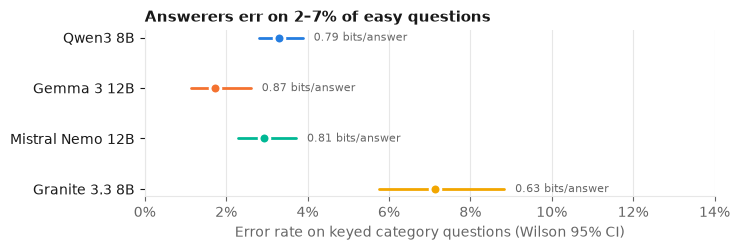

**Most frequent error types** (E1):

,answerer,predicate,target_category,n,errors,error_rate
0,Granite 3.3 8B,object,person,14,9,0.643
1,Gemma 3 12B,object,animal,12,8,0.667
2,Mistral Nemo 12B,object,person,19,8,0.421
3,Granite 3.3 8B,object,animal,15,7,0.467
4,Mistral Nemo 12B,object,animal,18,5,0.278
5,Qwen3 8B,object,person,20,4,0.200
6,Qwen3 8B,object,animal,18,4,0.222
7,Mistral Nemo 12B,person,person,39,4,0.103


**E1 outcome by whether the answerer made a keyed error** (observational):

,games_with_error,win_rate_with_error,games_without_error,win_rate_without_error
answerer,,,,
Qwen3 8B,11,0.000,149,0.456
Gemma 3 12B,9,0.556,151,0.437
Mistral Nemo 12B,15,0.533,145,0.462
Granite 3.3 8B,19,0.316,141,0.404


In [13]:
accuracy = ev.answer_accuracy()
display(accuracy.assign(answerer=accuracy.answerer.map(LABELS)))
overall = accuracy[accuracy.source == "all"].set_index("answerer").reindex(MODELS)
fig, ax = plt.subplots(figsize=(7.5, 2.6))
interval_dots(ax, overall.error_rate, overall.ci_low, overall.ci_high,
              [LABELS[m] for m in MODELS], [COLORS[m] for m in MODELS],
              "Error rate on keyed category questions (Wilson 95% CI)")
for y, m in enumerate(MODELS):
    ax.annotate(f"{overall.loc[m, 'capacity_bits']:.2f} bits/answer", (overall.loc[m, "ci_high"], y),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=8, color=INK2)
ax.xaxis.set_major_formatter(PCT); ax.set_xlim(0, 0.14)
ax.set_title("Answerers err on 2–7% of easy questions")
plt.tight_layout(); plt.show()
display(Markdown("**Most frequent error types** (E1):"))
display(ev.answer_errors_by_predicate().head(8).replace(LABELS))
display(Markdown("**E1 outcome by whether the answerer made a keyed error** (observational):"))
display(label_models(ev.answer_error_cost()))

* **Error rates on easy questions are 2–7%:** Gemma 3 1.7%, Qwen3 3.3%, Mistral 2.9%,
  Granite 7.1%. That caps information at roughly 0.63–0.87 bits per answer instead of 1.
* **Typical errors** are calling an animal or person an "object", or denying that a pangolin
  or okapi is a mammal.
* **Rates vary by experiment:** Qwen3 errs more on E2's model-picked (often rare) secrets
  (5.9%) than in E1 (2.4%).
* **Cost:** when Qwen3 gave a keyed wrong answer in E1, the guesser won 0 of 11 games (vs 46%
  otherwise). Pooled over the other answerers there is no clear effect, and these groups are
  small and non-randomized. The randomized evidence on cost is in Section 5.
* **No sign of deliberate misleading:** an answerer's identity does not change E1 outcomes
  (Section 1.2).

## 5. Lies and noise (E3, E4) vs theory

Qwen3 8B is the fixed answerer and the controller flips its answers.

* **E3:** 0, 1 or 2 scheduled lies, with or without a warning; warned/unwarned games are paired
  on target and flip schedule.
* **E4:** each answer is flipped independently with probability 5%, 10% or 17%.
* The guesser sees all 128 candidates, so the noiseless ideal is 7 questions.

**Theoretical references** (proposal, *Lies and noise*):

* For *k* adversarial lies, the Berlekamp volume bound gives the minimum number of questions,
  2^q ≥ N·Σᵢ₌₀ᵏ C(q, i).
* For random flips at rate ε, each answer carries at most 1 − h(ε) bits, so about
  log₂ N / (1 − h(ε)) questions are needed.

,min_questions,extra_questions
condition,,
0 lies (adversarial bound),7.000,0.000
1 lie (adversarial bound),11.000,4.000
2 lies (adversarial bound),14.000,7.000
5% random flips (capacity 0.71 bits),9.809,2.809
10% random flips (capacity 0.53 bits),13.183,6.183
17% random flips (capacity 0.34 bits),20.450,13.450


,lies,warned,games,win_rate,ci_low,ci_high,delivered_share,mean_turns
0,0,False,83,0.145,0.085,0.236,NaN,18.590
1,0,True,83,0.133,0.076,0.222,NaN,18.699
2,1,False,84,0.083,0.041,0.162,0.798,19.202
3,1,True,84,0.071,0.033,0.147,0.857,19.405
4,2,False,83,0.048,0.019,0.117,0.855,19.434
5,2,True,83,0.084,0.041,0.164,0.807,19.253


,flip_probability,games,win_rate,ci_low,ci_high,realized_flip_rate,capacity_bits,reference_questions,source
0,0.000,83,0.145,0.085,0.236,0.000,1.000,7.000,"E3 (0 lies, unwarned)"
1,0.050,100,0.080,0.041,0.150,0.051,0.714,9.809,E4
2,0.100,100,0.050,0.022,0.112,0.096,0.531,13.183,E4
3,0.170,100,0.070,0.034,0.137,0.177,0.342,20.450,E4


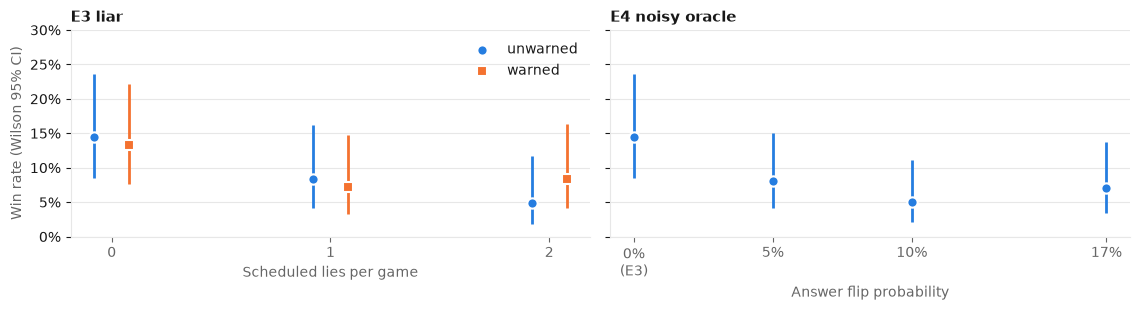

**E3 win rate by guesser and lie count:**

,0,1,2
Qwen3 8B,0.452,0.238,0.214
Gemma 3 12B,0.000,0.000,0.000
Mistral Nemo 12B,0.000,0.000,0.000
Granite 3.3 8B,0.100,0.071,0.048


**Warning effect** (warned − unwarned, paired on target and flip schedule):

,lies,n_pairs,mean_difference,ci_low,ci_high,p_value
0,0,83,-0.012,-0.072,0.048,1.000
1,1,84,-0.012,-0.071,0.048,1.000
2,2,83,0.036,-0.024,0.096,0.456


E3 lies vs win (within-guesser permutation): r = -0.101, p = 0.0171
E4 flip rate vs win (within-guesser permutation): r = -0.012, p = 0.8430


In [14]:
display(ev.theory_table())
liar = ev.liar_table()
display(liar)
noise = ev.noise_table()
display(noise)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.2), sharey=True)
for warned, marker, offset in ((False, "o", -0.08), (True, "s", 0.08)):
    rows = liar[liar.warned == warned]
    x = rows.lies + offset
    axes[0].vlines(x, rows.ci_low, rows.ci_high, color="#257de0" if not warned else "#f47230", linewidth=2)
    axes[0].scatter(x, rows.win_rate, marker=marker, s=55, zorder=3, edgecolor="white", linewidth=1.5,
                    color="#257de0" if not warned else "#f47230", label="warned" if warned else "unwarned")
axes[0].set_xticks([0, 1, 2]); axes[0].set_xlabel("Scheduled lies per game")
axes[0].legend(frameon=False, loc="upper right"); axes[0].set_title("E3 liar")
axes[1].vlines(noise.flip_probability, noise.ci_low, noise.ci_high, color="#257de0", linewidth=2)
axes[1].scatter(noise.flip_probability, noise.win_rate, s=55, color="#257de0", edgecolor="white",
                linewidth=1.5, zorder=3)
axes[1].set_xticks(noise.flip_probability, ["0%\n(E3)", "5%", "10%", "17%"])
axes[1].set_xlabel("Answer flip probability"); axes[1].set_title("E4 noisy oracle")
axes[0].set_ylabel("Win rate (Wilson 95% CI)")
axes[0].yaxis.set_major_formatter(PCT); axes[0].set_ylim(0, 0.3)
for ax in axes: ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

display(Markdown("**E3 win rate by guesser and lie count:**"))
display(label_models(ev.liar_by_guesser()))
display(Markdown("**Warning effect** (warned − unwarned, paired on target and flip schedule):"))
display(ev.warning_effect())
e3_trend = ev.stratified_trend_test(list(ev.load("e3")), lambda r: r["condition"]["lie_count"], ev.SEED)
e4_trend = ev.stratified_trend_test(list(ev.load("e4")), lambda r: r["condition"]["flip_probability"], ev.SEED + 1)
print(f"E3 lies vs win (within-guesser permutation): r = {e3_trend['correlation']:+.3f}, p = {e3_trend['p_value']:.4f}")
print(f"E4 flip rate vs win (within-guesser permutation): r = {e4_trend['correlation']:+.3f}, p = {e4_trend['p_value']:.4f}")

* **Baseline:** even without injected lies, only 14% of 128-candidate games are won against
  Qwen3's answers. Mean game length is 18.6 turns. Qwen3 is the only guesser that wins, and
  Gemma 3 and Mistral almost never guess (Section 1.6). Guessers are far from the 7-question
  ideal before any noise.
* **Lies reduce wins** from 14% to 8% (1 lie) and 5–8% (2 lies): a significant within-guesser
  trend (p ≈ 0.02).
* **Warnings do not help:** no warned−unwarned difference is significant at any lie count.
* **Random noise:** wins are 5–8% at 5–17% flips, below the 0-lie baseline, but with no
  dose-response trend in E4 itself (p ≈ 0.84). The floor is set by the guessers' weak
  baseline, not by the noise. The theoretical cost of 2.8–13.5 extra questions mostly cannot
  be observed when games are lost anyway.
* **Lie delivery:** 80–86% of scheduled lies were actually delivered; the rest fell after the
  game ended. Comparisons above use the **assigned** condition (intention-to-treat).

In [15]:
display(Markdown("**Do guessers re-check an answer after a lie?** Share of answers whose question is re-asked later in the game:"))
display(ev.recheck_rates().rename(LABELS, level=1))
display(Markdown("**E3 outcome by delivered lies** (observational; see caveat):"))
display(ev.outcome_after_flip())

**Do guessers re-check an answer after a lie?** Share of answers whose question is re-asked later in the game:

answers           recheck_rate          
answer                      flipped unflipped      flipped unflipped
experiment guesser                                                  
E3         Qwen3 8B          80.000  1508.000        0.013     0.000
           Gemma 3 12B      126.000  2393.000        0.008     0.010
           Mistral Nemo 12B 117.000  2317.000        0.632     0.675
           Granite 3.3 8B    92.000  1760.000        0.022     0.012
E4         Qwen3 8B         112.000   832.000        0.009     0.004
           Gemma 3 12B      154.000  1346.000        0.019     0.016
           Mistral Nemo 12B 157.000  1321.000        0.688     0.645
           Granite 3.3 8B   137.000  1108.000        0.066     0.046

**E3 outcome by delivered lies** (observational; see caveat):

,scheduled_lies,delivered,games,win_rate,mean_turns
0,1,0,29,0.310,16.759
1,1,1,139,0.029,19.835
2,2,0,12,0.417,16.333
3,2,1,32,0.156,18.031
4,2,2,122,0.008,19.984


* **Guessers almost never re-check a flipped answer.** Qwen3, Gemma 3 and Granite re-ask
  1–7% of questions whether or not the answer was flipped. Mistral's ~65% re-ask rate is the
  same with or without a flip, so it reflects its general looping rather than a response to
  the lie. No model detects and repairs lies the way robust search with lies requires.
* **Delivered vs scheduled:** games where a scheduled lie was *not* delivered were won far more
  often. This is survival bias, not a causal effect: lies are scheduled on later turns, so
  games won early end before the lie arrives. Use the assigned-condition comparison above for
  causal claims.

## 6. Summary of findings

| Question | Finding | Strength of evidence |
|---|---|---|
| RQ1 Who matters? | **The guesser.** E1 guesser win rates: Qwen3 76%, Gemma 3 69%, Granite 28%, Mistral 0%. Answerer identity has no significant effect. | Strong: Holm-corrected paired tests, clustered CIs |
| RQ1 Self-play? | **No self-play advantage**: same-model effect ≈ 0 pp (95% CI about ±6 pp). | Strong (null with a tight CI) |
| RQ1 Generalization | With 128 candidates only Qwen3 stays competent. Gemma 3 never guesses in any of its 521 E2–E4 games. | Strong; the cause (list length vs prompt) is confounded |
| RQ2 Randomness | **Picks are highly non-random**: 8–19 distinct of 128, entropy 2.5–3.6 bits vs about 6.0 for uniform, p < 0.0001. | Strong |
| RQ2 Exploitable? | **Yes, for a guesser that uses it**: a top-5 report lifts Qwen3 from 46% to 80% (5.7 turns saved, close to its 4.5-bit gap). No gain for models that don't guess. | Strong (paired, 80 pairs per model) |
| RQ3 Question quality | Qwen3 and Gemma 3 choose 89–96% of the best available bits and match a greedy information-maximizer. Mistral 62%; Granite good questions but 70% invalid moves. | Moderate: a closed-menu pilot |
| RQ3 Reasoning | **More thinking does not help**: no significant gain at 256 or 1024 tokens, at 35–125× the time. | Pilot (40 targets, truncated reasoning) |
| RQ4 Answer accuracy | Easy-question error rates are 1.7–7.1% (Gemma 3 best, Granite worst), capping each answer at 0.63–0.87 bits. | Moderate: partial key, category questions only |
| Lies & noise | Lies lower wins (14% → 5–8%, trend p ≈ 0.02). Warnings don't help, and guessers rarely re-check flipped answers. | Moderate: low baseline win rate limits power |

### Limitations

* **Answer key:** answer accuracy and free-form information gain are measured only on keyed
  category questions or E5's closed menu. Open-ended answer accuracy still needs the planned
  answer key (judge model plus human review).
* **Secrets:** E1 uses 40 fixed targets, so conclusions are about this pool. The common/rare
  labels are project-curated strata.
* **Precision:** Gemma 3 runs in FP32 and the other models in FP16, a possible confound in
  comparisons involving Gemma.
* **E3/E4:** Qwen3's own answers, not a gold oracle, are the baseline. The low baseline win
  rate leaves little room to see the cost of noise.
* **E6:** budget forcing truncates reasoning in most calls, so it compares cut-off reasoning
  rather than models that finish thinking.
* **Prompt version:** all runs use the original v1 prompts. The guess rule was fixed, and the
  invalid v1 data is excluded.